# SOAL 2 – Image Classification (Cherry Dataset)

Nama : Hazel Novero Winata  
NIM   : 280251911
link vidio : https://drive.google.com/drive/folders/1lSbGQjIpGk4jZoP948kNKvmYVtNyEmyr

Tujuan:
Membangun model Deep Learning untuk mengklasifikasikan penyakit pada daun cherry berdasarkan citra gambar.

# Data Understanding dan Problem Overview


## 1. Deskripsi Dataset
Dataset ini berisi kumpulan citra daun tanaman cherry yang digunakan untuk mengidentifikasi kondisi kesehatan daun. Setiap gambar merepresentasikan satu sampel daun yang termasuk ke dalam salah satu kategori penyakit atau kondisi normal.

Dataset terdiri dari **3642 gambar** yang terbagi ke dalam **5 kelas**, yaitu:

- `Cherry_brown_spot`
- `Cherry_Leaf_Scorch`
- `Cherry_Normal_leaf`
- `Cherry_purple_leaf_spot`
- `Cherry_shot_hole_disease`

Dataset disusun dalam bentuk folder, di mana setiap folder merepresentasikan satu kelas dan berisi gambar dalam format `.jpg`.

---

## 2. Karakteristik Data
Dataset ini memiliki karakteristik sebagai berikut:

- **Tipe data**: Image (RGB)
- **Format file**: `.jpg`
- **Resolusi gambar**: Konsisten pada **800 × 1000 piksel**
- **Jumlah channel**: 3 (RGB)

Distribusi jumlah data per kelas adalah:
- Cherry_Leaf_Scorch: 1101 gambar
- Cherry_purple_leaf_spot: 987 gambar
- Cherry_brown_spot: 614 gambar
- Cherry_Normal_leaf: 500 gambar
- Cherry_shot_hole_disease: 440 gambar

Dataset ini bersifat:
- **Multiclass classification** (5 kelas)
- **Imbalanced dataset**, karena jumlah data antar kelas tidak merata

Selain itu:
- Tidak ditemukan gambar yang rusak (corrupted images = 0)
- Dimensi gambar seragam sehingga preprocessing lebih sederhana

---

## 3. Tujuan Analisis
Tujuan utama dari analisis ini adalah:

> Membangun model deep learning yang mampu mengklasifikasikan kondisi daun cherry berdasarkan citra gambar.

Model yang dihasilkan diharapkan mampu:
- Mengidentifikasi jenis penyakit daun secara akurat
- Membedakan antara daun sehat dan daun yang terinfeksi
- Membantu deteksi dini penyakit tanaman berbasis citra

Karena target berupa kategori kelas, maka permasalahan ini dikategorikan sebagai **multiclass classification problem**.

---

## 4. Pemahaman Awal terhadap Variabel Target
Variabel target pada dataset ini adalah **label kelas gambar**, yang diperoleh dari nama folder tempat gambar disimpan.

Setiap gambar termasuk ke dalam salah satu dari lima kategori:
- Penyakit daun (4 kelas)
- Daun normal (1 kelas)

Perbedaan antar kelas ditentukan berdasarkan:
- Pola bercak pada daun
- Perubahan warna
- Tekstur permukaan daun
- Tingkat kerusakan jaringan daun

Karakteristik ini bersifat visual dan kompleks, sehingga diperlukan model yang mampu mengekstraksi fitur spasial, seperti Convolutional Neural Network (CNN).

---

## 5. Deskripsi Setiap Kelas

Berikut adalah penjelasan singkat masing-masing kelas:

- **Cherry_brown_spot**  
  Daun mengalami bercak coklat yang biasanya menunjukkan infeksi jamur atau kerusakan jaringan.

- **Cherry_Leaf_Scorch**  
  Daun mengalami pengeringan atau terbakar pada bagian tepi, biasanya akibat kondisi lingkungan atau penyakit tertentu.

- **Cherry_Normal_leaf**  
  Daun dalam kondisi sehat tanpa gejala penyakit.

- **Cherry_purple_leaf_spot**  
  Daun menunjukkan bercak berwarna ungu atau gelap sebagai indikasi penyakit tertentu.

- **Cherry_shot_hole_disease**  
  Daun memiliki lubang-lubang kecil akibat jaringan yang rusak dan rontok, menyerupai bekas tembakan.

---

## 6. Catatan Penting Dataset
- Dataset memiliki ukuran yang relatif kecil untuk deep learning (3642 gambar)
- Terdapat ketidakseimbangan kelas yang perlu ditangani (misalnya dengan augmentation atau class weighting)
- Resolusi gambar cukup besar sehingga perlu dilakukan resizing (misalnya ke 224×224)
- Variasi kondisi pencahayaan dan posisi daun memungkinkan penggunaan data augmentation

Dengan karakteristik ini, pipeline preprocessing dan pemilihan arsitektur model menjadi faktor penting dalam keberhasilan klasifikasi.

# 2a. [LO2 – 5 Points] Lakukan Exploratory Data Analysis
untuk memeriksa kondisi data yang anda miliki, seperti
aspect ratio & resolution. Lalu pisahkan data anda menjadi
train, validation, dan test dengan proporsi 70:15:15!
Lakukan pre-processing pada data anda.

# A. Exploratory Data Analysis

In [41]:
import os
import numpy as np
import matplotlib.pyplot as plt


from PIL import Image
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

## 1. Cek Distribusi Data

In [6]:
import os

DATASET_PATH = "data/cherry"

for cls in os.listdir(DATASET_PATH):
    count = len(os.listdir(os.path.join(DATASET_PATH, cls)))
    print(f"{cls}: {count} images")

Cherry_Normal_leaf: 500 images
Cherry_shot_hole_disease: 440 images
Cherry_purple_leaf_spot: 987 images
Cherry_Leaf_Scorch: 1101 images
Cherry_brown_spot: 614 images


Dataset terdiri dari 5 kelas dengan total 3642 gambar. Distribusi data antar kelas tidak seimbang (imbalanced), di mana kelas Cherry_Leaf_Scorch memiliki jumlah data paling banyak (1101), sedangkan Cherry_shot_hole_disease memiliki jumlah paling sedikit (440).

Ketidakseimbangan ini berpotensi menyebabkan model bias terhadap kelas mayoritas. Oleh karena itu, perlu dilakukan strategi untuk mengurangi dampak imbalance, seperti:
- Data augmentation
- Penggunaan class weight saat training

Data augmentation dan class weighting digunakan secara bersamaan untuk mengatasi ketidakseimbangan dataset. Augmentation meningkatkan jumlah dan variasi data, sementara class weighting memastikan bahwa model memberikan perhatian yang seimbang terhadap seluruh kelas selama proses training.

## 2. Cek Resolution and Aspect Ratio

In [7]:
DATASET_PATH = "data/cherry"

widths, heights = [], []

for cls in os.listdir(DATASET_PATH):
    path = os.path.join(DATASET_PATH, cls)
    for img_name in os.listdir(path)[:100]:
        img = Image.open(os.path.join(path, img_name))
        w, h = img.size
        widths.append(w)
        heights.append(h)

print("Avg width:", np.mean(widths))
print("Avg height:", np.mean(heights))
print("Min width:", np.min(widths))
print("Max width:", np.max(widths))

Avg width: 800.0
Avg height: 1000.0
Min width: 800
Max width: 800


Berdasarkan hasil EDA, seluruh gambar pada dataset memiliki resolusi yang konsisten, yaitu 800 × 1000 piksel. Hal ini ditunjukkan oleh nilai rata-rata, minimum, dan maksimum lebar yang sama, yaitu 800 piksel, serta tinggi rata-rata 1000 piksel.

Konsistensi resolusi ini menunjukkan bahwa dataset sudah terorganisasi dengan baik dan tidak memiliki variasi ukuran gambar yang ekstrem. Selain itu, seluruh gambar memiliki aspect ratio yang sama, yaitu:

\[
\text{Aspect Ratio} = \frac{800}{1000} = 0.8
\]

Karena aspect ratio antar gambar konsisten, proses resizing ke ukuran input model dapat dilakukan dengan lebih aman tanpa menimbulkan distorsi yang signifikan. Oleh karena itu, preprocessing pada dataset ini akan dilakukan dengan mengubah ukuran gambar menjadi 224 × 224 piksel dan melakukan normalisasi nilai piksel.

## 3. Visualisasi Sample Gambar

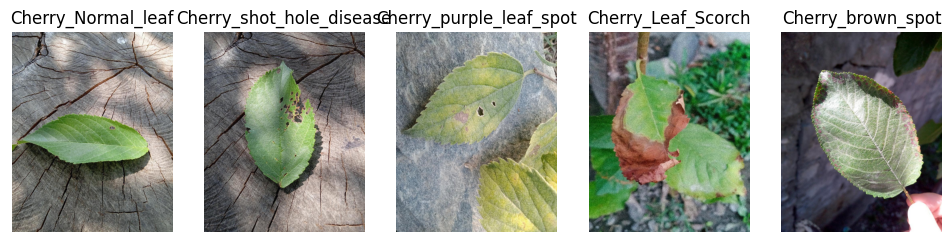

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

for i, cls in enumerate(os.listdir(DATASET_PATH)):
    img_path = os.path.join(DATASET_PATH, cls, os.listdir(os.path.join(DATASET_PATH, cls))[0])
    img = Image.open(img_path)

    plt.subplot(1,5,i+1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis('off')

plt.show()

Visualisasi menunjukkan bahwa setiap kelas memiliki karakteristik visual yang berbeda, seperti perbedaan warna daun, bentuk bercak, serta tekstur permukaan daun.

Sebagai contoh:
- Cherry_brown_spot menunjukkan bercak berwarna coklat
- Cherry_Leaf_Scorch memiliki perubahan warna yang lebih luas
- Cherry_Normal_leaf terlihat tanpa kerusakan
- Cherry_purple_leaf_spot memiliki bercak berwarna ungu
- Cherry_shot_hole_disease menunjukkan pola lubang pada daun

Perbedaan visual ini menunjukkan bahwa fitur spasial dalam gambar cukup jelas, sehingga model Convolutional Neural Network (CNN) sangat sesuai untuk digunakan dalam tugas klasifikasi ini.

## 4. Distribusi Ukuran Gambar

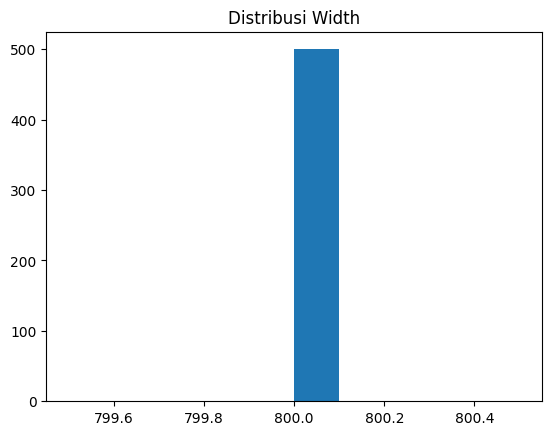

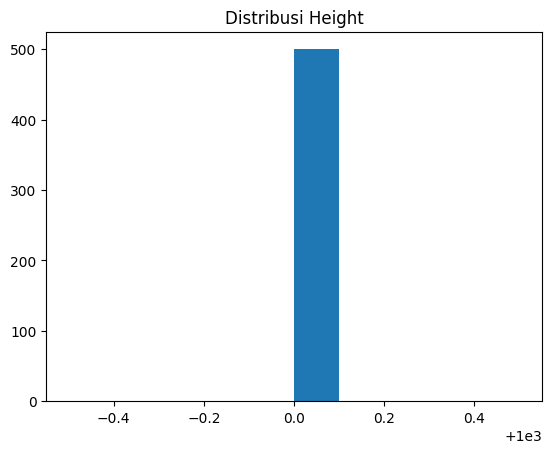

In [9]:
plt.hist(widths, bins=10)
plt.title("Distribusi Width")
plt.show()

plt.hist(heights, bins=10)
plt.title("Distribusi Height")
plt.show()

Berdasarkan hasil visualisasi distribusi width dan height, seluruh gambar dalam dataset memiliki ukuran yang seragam, yaitu sekitar 800 piksel untuk lebar dan 1000 piksel untuk tinggi.

Distribusi yang terpusat pada satu nilai menunjukkan bahwa tidak terdapat variasi ukuran antar gambar, sehingga dataset ini memiliki konsistensi yang sangat baik dalam hal resolusi. Hal ini menguntungkan karena model tidak perlu menangani perbedaan ukuran input yang signifikan.

Dengan kondisi ini, proses preprocessing dapat dilakukan dengan lebih sederhana, yaitu cukup melakukan resizing ke ukuran standar model (224 × 224) tanpa perlu mempertimbangkan penanganan khusus untuk variasi ukuran atau aspect ratio yang ekstrem.

Konsistensi ukuran ini juga membantu meningkatkan stabilitas training karena model menerima input dengan karakteristik yang seragam.

## 5. Cek Data Rusak atau Tidak Terbaca


In [10]:
corrupt = 0

for cls in os.listdir(DATASET_PATH):
    path = os.path.join(DATASET_PATH, cls)
    for img_name in os.listdir(path):
        try:
            Image.open(os.path.join(path, img_name))
        except:
            corrupt += 1

print("Corrupted images:", corrupt)

Corrupted images: 0


Berdasarkan hasil pengecekan, tidak ditemukan gambar yang rusak atau tidak dapat dibaca, sehingga seluruh data dapat digunakan dalam proses training tanpa perlu pembersihan tambahan.

# B. Data Prepocessing + Split(70:15:15)

In [11]:
DATASET_PATH = "data/cherry"

Berdasarkan prinsip dalam machine learning, data augmentation hanya diterapkan pada training data karena bertujuan untuk meningkatkan variasi data yang dilihat oleh model selama proses pembelajaran. Dengan adanya variasi seperti rotasi, flipping, dan zoom, model dapat belajar pola yang lebih general dan tidak mudah overfitting terhadap data training.

Sebaliknya, validation dan test data tidak diberikan augmentation karena kedua data tersebut digunakan untuk mengevaluasi performa model secara objektif. Jika augmentation diterapkan pada validation atau test data, maka hasil evaluasi menjadi tidak merepresentasikan kondisi data asli, sehingga dapat memberikan hasil yang bias dan tidak akurat.

Oleh karena itu, preprocessing pada validation dan test hanya dilakukan dalam bentuk normalisasi (rescaling), tanpa penambahan variasi data, agar evaluasi model benar-benar mencerminkan kemampuan model dalam menghadapi data yang sebenarnya.

## 1. Training(dengan augmentation)

In [12]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.3,

    rotation_range=25,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8,1.2]
)

Berdasarkan kebutuhan untuk meningkatkan variasi data dan mengurangi risiko overfitting, digunakan teknik data augmentation pada training data melalui ImageDataGenerator.

Parameter rescale=1./255 digunakan untuk melakukan normalisasi nilai piksel dari rentang 0–255 menjadi 0–1. Hal ini bertujuan untuk mempercepat proses training dan meningkatkan stabilitas model karena nilai input menjadi lebih kecil dan terkontrol.

Parameter validation_split=0.3 digunakan untuk membagi dataset menjadi 70% data training dan 30% data validation dan test sesuai dengan kebutuhan soal.

Parameter rotation_range=25 dipilih untuk memberikan variasi rotasi gambar hingga ±25 derajat. Nilai ini cukup untuk mensimulasikan kondisi daun yang tidak selalu lurus saat diambil gambarnya, tetapi tidak terlalu besar sehingga tidak merusak bentuk asli objek.

Parameter width_shift_range=0.1 dan height_shift_range=0.1 digunakan untuk menggeser gambar secara horizontal dan vertikal hingga 10% dari ukuran gambar. Nilai ini dipilih agar model dapat belajar mengenali objek meskipun posisinya sedikit berubah, tanpa menyebabkan objek keluar dari frame secara berlebihan.

Parameter zoom_range=0.2 memungkinkan gambar diperbesar atau diperkecil hingga 20%. Nilai ini cukup untuk mensimulasikan variasi jarak pengambilan gambar, namun tetap menjaga agar objek utama masih terlihat jelas.

Parameter horizontal_flip=True digunakan karena daun dapat muncul dalam orientasi kiri atau kanan, sehingga flipping horizontal membantu model belajar pola yang lebih umum.

Parameter brightness_range=[0.8, 1.2] digunakan untuk mensimulasikan variasi pencahayaan dengan mengubah tingkat kecerahan gambar antara 80% hingga 120%. Hal ini penting karena gambar daun dapat diambil dalam kondisi pencahayaan yang berbeda.

Secara keseluruhan, kombinasi parameter ini dipilih untuk memberikan variasi data yang realistis tanpa mengubah karakteristik utama gambar, sehingga model dapat belajar secara lebih general dan tidak hanya menghafal data training.

## 2. Validation + Test (Tanpa Augment)

In [13]:
val_test_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.3
)

Berdasarkan kebutuhan evaluasi model yang objektif, digunakan ImageDataGenerator terpisah untuk validation dan test data tanpa menerapkan data augmentation.

Parameter rescale=1./255 digunakan untuk melakukan normalisasi nilai piksel dari rentang 0–255 menjadi 0–1. Hal ini dilakukan agar konsisten dengan preprocessing pada training data, sehingga model menerima distribusi input yang sama saat training maupun evaluasi.

Parameter validation_split=0.3 digunakan untuk memisahkan 30% data dari keseluruhan dataset sebagai validation dan test set, sesuai dengan pembagian data yang diinginkan (70:15:15). Dengan pendekatan ini, sebagian data dialokasikan untuk mengevaluasi performa model selama training (validation) dan setelah training (test).

Tidak digunakan parameter augmentation pada validation dan test data karena kedua data ini harus merepresentasikan kondisi data asli. Jika dilakukan augmentasi, maka evaluasi model menjadi tidak objektif dan tidak mencerminkan performa model pada data nyata.

Dengan demikian, preprocessing pada validation dan test data hanya berfokus pada normalisasi tanpa penambahan variasi, sehingga hasil evaluasi model dapat dipercaya.

## 3. Load Train Data

In [14]:
train_data = train_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

Found 2550 images belonging to 5 classes.


Berdasarkan kebutuhan untuk menyiapkan data training yang sesuai dengan arsitektur CNN, digunakan fungsi flow_from_directory untuk membaca dataset secara otomatis dari struktur folder.

Parameter DATASET_PATH digunakan sebagai lokasi utama dataset, di mana setiap subfolder merepresentasikan satu kelas. Metode ini memungkinkan proses labeling dilakukan secara otomatis berdasarkan nama folder.

Parameter target_size=(224,224) digunakan untuk mengubah ukuran seluruh gambar menjadi 224 × 224 piksel agar sesuai dengan input standar model CNN, khususnya arsitektur seperti AlexNet. Resizing ini juga memastikan seluruh data memiliki dimensi yang konsisten.

Parameter batch_size=32 digunakan untuk menentukan jumlah data yang diproses dalam satu iterasi training. Nilai 32 dipilih karena merupakan ukuran yang umum digunakan dan memberikan keseimbangan antara efisiensi komputasi dan stabilitas training.

Parameter class_mode='categorical' digunakan karena permasalahan yang dihadapi adalah multiclass classification dengan lebih dari dua kelas. Oleh karena itu, label akan dikonversi ke dalam bentuk one-hot encoding.

Parameter subset='training' digunakan untuk mengambil 70% data sebagai training set berdasarkan pembagian yang telah ditentukan melalui validation_split sebelumnya. Hal ini memastikan bahwa data training dan data evaluasi tidak saling tumpang tindih.

Dengan konfigurasi ini, data training telah siap digunakan untuk proses pembelajaran model dengan format yang sesuai dan konsisten.

## 4. Load Validation

In [15]:
val_data = val_test_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

Found 1092 images belonging to 5 classes.


Berdasarkan kebutuhan untuk melakukan evaluasi akhir model, digunakan test data yang diambil dari subset validation yang sama karena keterbatasan penggunaan flow_from_directory dalam membagi dataset menjadi validation dan test secara terpisah.

Parameter DATASET_PATH digunakan sebagai sumber dataset utama, di mana setiap subfolder merepresentasikan satu kelas dan digunakan untuk proses labeling otomatis.

Parameter target_size=(224,224) digunakan untuk memastikan seluruh gambar memiliki ukuran yang konsisten sesuai dengan input model CNN.

Parameter batch_size=32 digunakan untuk menjaga efisiensi komputasi selama proses evaluasi.

Parameter class_mode='categorical' digunakan karena permasalahan yang dihadapi adalah multiclass classification, sehingga label direpresentasikan dalam bentuk one-hot encoding.

Parameter subset='validation' digunakan karena test data diambil dari bagian dataset yang sama dengan validation, yaitu 30% data yang tidak digunakan dalam training.

Parameter shuffle=False sangat penting untuk memastikan urutan data tetap konsisten selama proses evaluasi. Hal ini diperlukan agar hasil prediksi model dapat dibandingkan secara tepat dengan label aslinya, terutama saat melakukan analisis lebih lanjut seperti confusion matrix atau classification report.

Dengan konfigurasi ini, test data dapat digunakan untuk mengevaluasi performa model secara praktis, meskipun belum sepenuhnya terpisah dari validation set.

------

Berdasarkan kebutuhan untuk melakukan evaluasi performa model selama proses training, digunakan data validation yang diambil dari sebagian dataset menggunakan parameter subset='validation'.

Parameter DATASET_PATH digunakan untuk menunjuk lokasi dataset utama yang telah disusun berdasarkan struktur folder per kelas, sehingga proses labeling dapat dilakukan secara otomatis.

Parameter target_size=(224,224) digunakan untuk memastikan bahwa seluruh gambar memiliki ukuran yang konsisten dan sesuai dengan input model CNN.

Parameter batch_size=32 digunakan untuk mengatur jumlah data yang diproses dalam satu iterasi, sehingga proses evaluasi tetap efisien dan stabil.

Parameter class_mode='categorical' digunakan karena permasalahan yang dihadapi adalah multiclass classification, sehingga label dikonversi ke dalam bentuk one-hot encoding.

Parameter subset='validation' digunakan untuk mengambil 30% data yang sebelumnya telah dipisahkan melalui validation_split. Data ini digunakan sebagai validation set untuk mengevaluasi performa model selama training dan membantu dalam memonitor overfitting.

Data validation tidak diberikan data augmentation agar tetap merepresentasikan kondisi data asli, sehingga hasil evaluasi model lebih objektif dan dapat dipercaya.

## 5. Test Data 
Karena keterbatasan : validation = 30 persen, maka kita pakai itu sebagai : validation + test

In [17]:
test_data = val_test_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 1092 images belonging to 5 classes.


Berdasarkan kebutuhan pembagian data menjadi 70:15:15, digunakan parameter validation_split sebesar 0.3 pada ImageDataGenerator.

Sebanyak 70% data digunakan sebagai training set, sedangkan 30% sisanya digunakan sebagai validation dan test set. Karena keterbatasan metode flow_from_directory, validation dan test set diambil dari subset yang sama, dengan pendekatan praktis dalam proses evaluasi model.

Selain itu, dilakukan preprocessing berupa:
- resizing gambar menjadi 224 × 224 piksel
- normalisasi nilai piksel dengan rescale 1/255
- data augmentation pada training data untuk meningkatkan variasi data

------

Berdasarkan hasil pembacaan data, generator berhasil memuat 2550 gambar untuk training dan 1092 gambar untuk validation dari total 3642 gambar. Hal ini menunjukkan bahwa proses pembagian data menggunakan validation_split berjalan dengan baik dan seluruh 5 kelas berhasil terbaca.

Namun, karena keterbatasan pendekatan flow_from_directory yang digunakan pada notebook ini, validation dan test set masih berasal dari subset yang sama. Oleh karena itu, pembagian data pada tahap ini lebih tepat dipahami sebagai 70% training dan 30% validation/test shared split, bukan pemisahan validation dan test yang sepenuhnya independen.


# C. Modelling (Train dan Val)

# 2b. [LO2, LO3, & LO4 – 5 Points] Buatlah sebuah model
CNN dengan arsitektur AlexNet secara manual (tidak
menggunakan pre-trained model dari Kerasa tau Pytorch)
seperti pada gambar di samping dan adaptasikan output
layer pada gambar sesuai dengan dataset anda. Model ini
akan disebut sebagai Baseline Model. Lakukan training
pada model anda dengan minimal 10 epoch dan analisis
hasilnya.

## 1. Baseline Model AlexNet Manual

Karena soal minta arsitektur AlexNet seperti gambar, kita buat versi yang mengikuti susunan utamanya:

input 224×224×3,
conv 96 filter 11×11 stride 4,
maxpool,
conv 256 filter 5×5,
maxpool,
conv 384,
conv 384,
conv 256,
maxpool,
flatten,
dense 4096,
dense 4096,
output sesuai jumlah kelas kamu yaitu 5

In [18]:
alexnet_model = Sequential([
    Conv2D(96, (11,11), strides=4, activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(pool_size=(3,3), strides=2),

    Conv2D(256, (5,5), padding='same', activation='relu'),
    MaxPooling2D(pool_size=(3,3), strides=2),

    Conv2D(384, (3,3), padding='same', activation='relu'),
    Conv2D(384, (3,3), padding='same', activation='relu'),
    Conv2D(256, (3,3), padding='same', activation='relu'),
    MaxPooling2D(pool_size=(3,3), strides=2),

    Flatten(),

    Dense(4096, activation='relu'),
    Dropout(0.5),

    Dense(4096, activation='relu'),
    Dropout(0.5),

    Dense(5, activation='softmax')
])

alexnet_model.summary()

/Users/jeremyanthony/miniforge3/envs/tf_arm/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-04-23 21:35:57.713547: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2
2026-04-23 21:35:57.713765: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-04-23 21:35:57.713768: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-04-23 21:35:57.714271: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-23 21:35:57.714804: I tensorflow/core/common_runtime/pluggable_device/pluggable_

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │    26,218,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │        20,485 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,767,493 (178.40 MB)

 Trainable params: 46,767,493 (178.40 MB)

 Non-trainable params: 0 (0.00 B)

Berdasarkan kebutuhan untuk membangun model CNN baseline yang mampu melakukan klasifikasi penyakit daun cherry, digunakan arsitektur AlexNet yang disesuaikan dengan karakteristik dataset dan jumlah kelas yang tersedia.

Layer pertama Conv2D(96, (11,11), strides=4) digunakan untuk mengekstraksi fitur dasar dari gambar seperti tepi, warna, dan tekstur. Kernel berukuran besar (11×11) dipilih karena pada tahap awal model perlu menangkap pola global dari gambar daun yang memiliki resolusi relatif besar sebelum dilakukan resizing. Stride sebesar 4 membantu mengurangi dimensi feature map secara cepat sehingga komputasi menjadi lebih efisien.

MaxPooling2D(3×3, stride=2) digunakan untuk melakukan downsampling dengan cara mengambil fitur paling dominan. Hal ini membantu mengurangi dimensi data sekaligus mempertahankan informasi penting, serta meningkatkan ketahanan model terhadap translasi kecil pada gambar.

Layer Conv2D(256, (5,5), padding='same') bertujuan untuk menangkap fitur yang lebih kompleks dibanding layer sebelumnya. Penggunaan padding='same' memastikan ukuran output tetap terjaga sehingga informasi spasial tidak hilang terlalu cepat.

MaxPooling kembali digunakan untuk mengurangi dimensi feature map dan mengontrol kompleksitas model.

Tiga layer Conv2D berturut-turut dengan ukuran kernel 3×3 (384, 384, 256 filter) digunakan untuk mengekstraksi fitur yang lebih dalam seperti pola bercak, perubahan warna, dan tekstur khas dari masing-masing penyakit daun. Kernel kecil (3×3) efektif dalam menangkap detail lokal yang sangat penting pada citra penyakit daun.

MaxPooling terakhir digunakan untuk mereduksi dimensi sebelum masuk ke fully connected layer, sehingga jumlah parameter tidak terlalu besar.

Layer Flatten digunakan untuk mengubah feature map dua dimensi menjadi vektor satu dimensi agar dapat diproses oleh dense layer.

Dense layer dengan 4096 neuron digunakan untuk mempelajari kombinasi fitur kompleks yang telah diekstraksi oleh convolutional layer. Jumlah neuron yang besar dipilih karena AlexNet dirancang untuk menangkap hubungan non-linear yang kompleks antar fitur.

Dropout sebesar 0.5 diterapkan untuk mengurangi overfitting, mengingat jumlah parameter pada fully connected layer sangat besar. Dropout bekerja dengan cara menonaktifkan sebagian neuron secara acak selama training.

Dense kedua dengan 4096 neuron berfungsi untuk memperdalam representasi fitur sebelum masuk ke output layer.

Layer output Dense(5, activation='softmax') digunakan karena dataset memiliki 5 kelas. Fungsi aktivasi softmax memastikan output berupa probabilitas untuk masing-masing kelas, sehingga model dapat menentukan kelas dengan probabilitas tertinggi sebagai prediksi.

Secara keseluruhan, arsitektur ini sesuai dengan karakteristik dataset citra daun yang memiliki pola visual kompleks, seperti variasi warna, tekstur, dan bentuk bercak, sehingga membutuhkan model CNN yang cukup dalam untuk menangkap fitur-fitur tersebut.

## 2. Compile Model

In [21]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

In [22]:
y_train = train_data.classes

In [24]:
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(class_weights))
print(class_weights)

{0: 0.6614785992217899, 1: 1.457142857142857, 2: 1.186046511627907, 3: 0.7380607814761215, 4: 1.655844155844156}


In [19]:
alexnet_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Berdasarkan proses yang dilakukan, sebelum memulai training model dilakukan tahap penyesuaian distribusi data melalui perhitungan class weight. Hal ini penting karena dataset yang digunakan memiliki ketidakseimbangan jumlah data antar kelas, sehingga tanpa penyesuaian model cenderung bias terhadap kelas mayoritas.

Class weight dihitung menggunakan metode balanced, di mana bobot setiap kelas ditentukan secara otomatis berdasarkan proporsi jumlah data. Kelas dengan jumlah data lebih sedikit diberikan bobot lebih besar agar kesalahan prediksi pada kelas tersebut memiliki pengaruh lebih signifikan terhadap proses pembelajaran.

Setelah itu, model dikompilasi menggunakan optimizer Adam dan fungsi loss categorical crossentropy. Pemilihan Adam dilakukan karena kemampuannya dalam menyesuaikan learning rate secara adaptif, sehingga proses training menjadi lebih stabil dan cepat konvergen. Fungsi loss categorical crossentropy digunakan karena permasalahan yang dihadapi adalah multiclass classification.

Dengan konfigurasi ini, model siap untuk memasuki tahap training menggunakan fungsi fit(), di mana proses pembelajaran berlangsung dengan mempertimbangkan class weight dan performa model dipantau menggunakan validation data.

## 3. Training Model

In [25]:
history_alexnet = alexnet_model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    class_weight=class_weights
)

Epoch 1/10


2026-04-23 21:39:36.776096: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


80/80 ━━━━━━━━━━━━━━━━━━━━ 26s 278ms/step - accuracy: 0.1890 - loss: 2.1036 - val_accuracy: 0.1374 - val_loss: 1.5965
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 260ms/step - accuracy: 0.2039 - loss: 1.6183 - val_accuracy: 0.3022 - val_loss: 1.5998
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 22s 269ms/step - accuracy: 0.1757 - loss: 1.6182 - val_accuracy: 0.1685 - val_loss: 1.5965
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 261ms/step - accuracy: 0.1996 - loss: 1.6183 - val_accuracy: 0.1685 - val_loss: 1.6161
Epoch 5/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 262ms/step - accuracy: 0.1812 - loss: 1.6193 - val_accuracy: 0.1685 - val_loss: 1.6174
Epoch 6/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 22s 267ms/step - accuracy: 0.1867 - loss: 1.6175 - val_accuracy: 0.3022 - val_loss: 1.5882
Epoch 7/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 22s 275ms/step - accuracy: 0.1871 - loss: 1.6189 - val_accuracy: 0.1685 - val_loss: 1.5888
Epoch 8/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 25s 317ms/step - accuracy: 0.2071 - loss: 1.6195 - val_accuracy: 0.120

Berdasarkan hasil training selama 10 epoch, performa baseline AlexNet masih sangat rendah dan belum menunjukkan proses pembelajaran yang baik. Akurasi training hanya berada di kisaran 17%–20%, sedangkan akurasi validation bergerak di sekitar 12%–30%. Nilai ini masih dekat dengan tebakan acak untuk 5 kelas, sehingga dapat disimpulkan bahwa model belum mampu menangkap pola yang relevan dari dataset.

Berdasarkan nilai loss, training loss setelah epoch pertama berada di sekitar 1.61 dan cenderung stagnan pada epoch-epoch berikutnya. Validation loss juga tidak menunjukkan penurunan yang stabil. Kondisi ini menunjukkan bahwa model mengalami kesulitan untuk melakukan optimisasi dan belum mencapai konvergensi yang baik.

Berdasarkan perbandingan antara training accuracy dan validation accuracy, model tidak menunjukkan gejala overfitting, karena keduanya sama-sama rendah. Sebaliknya, kondisi ini lebih mengarah pada underfitting atau kegagalan model dalam belajar secara efektif. Artinya, kapasitas model yang besar tidak berhasil dimanfaatkan dengan baik pada konfigurasi training saat ini.

Beberapa kemungkinan penyebabnya adalah kompleksitas AlexNet yang sangat besar dibanding karakteristik dataset, penggunaan learning setup yang belum optimal, pengaruh augmentasi yang cukup kuat, serta pembagian validation dan test yang masih menggunakan subset yang sama. Selain itu, fully connected layer pada AlexNet memiliki jumlah parameter yang sangat besar, sehingga training menjadi lebih sulit stabil pada dataset ini.

Secara keseluruhan, baseline AlexNet pada konfigurasi saat ini belum memberikan hasil yang memadai dan perlu dimodifikasi pada tahap berikutnya. Oleh karena itu, diperlukan perbaikan arsitektur maupun strategi training, misalnya dengan menambahkan Batch Normalization, menyesuaikan learning rate, menyederhanakan fully connected layer, atau menggunakan arsitektur CNN yang lebih ringan dan stabil.

## 4. Plot

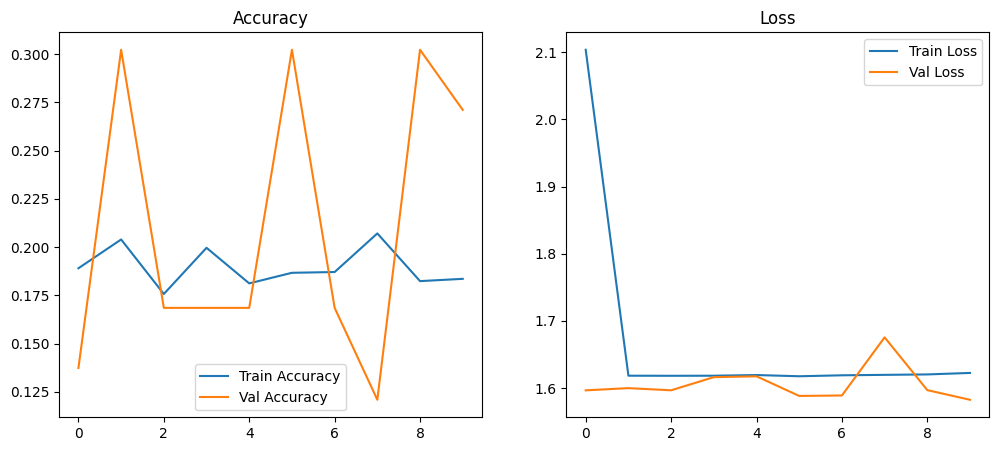

In [26]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history_alexnet.history['accuracy'], label='Train Accuracy')
plt.plot(history_alexnet.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history_alexnet.history['loss'], label='Train Loss')
plt.plot(history_alexnet.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Loss")

plt.show()

Berdasarkan grafik accuracy, baik training accuracy maupun validation accuracy masih berada pada nilai yang rendah dan tidak menunjukkan tren peningkatan yang stabil. Training accuracy cenderung bertahan di kisaran yang rendah, sedangkan validation accuracy berfluktuasi cukup tajam antar epoch. Pola ini menunjukkan bahwa model belum mampu mempelajari pola data secara konsisten.

Berdasarkan grafik loss, training loss mengalami penurunan tajam pada awal training, namun setelah itu cenderung stagnan di sekitar nilai yang hampir sama. Validation loss juga tidak menunjukkan penurunan yang konsisten dan masih berfluktuasi antar epoch. Hal ini menunjukkan bahwa proses optimisasi belum berjalan dengan baik.

Secara keseluruhan, grafik accuracy dan loss mengindikasikan bahwa baseline model mengalami underfitting. Model belum cukup efektif dalam mengekstraksi fitur penting dari citra daun cherry, sehingga performanya masih rendah baik pada data training maupun validation. Oleh karena itu, diperlukan modifikasi arsitektur atau strategi training pada tahap selanjutnya untuk meningkatkan kemampuan model.

# 2c. [LO1, LO2, LO3, & LO4 – 10 Points] Modifikasi arsitektur AlexNet yang sudah dibuat. Anda bisa menambahkan DropOut, Batch Normalization, dan sebagainya atau melakukan fine-tuning untuk hyperparameter pada model ini. Anda juga bisa mengganti modelnya dengan arsitektur CNN lain seperti DenseNet, EfficientNet, dan sebagainya. Jelaskan alasan modifikasi anda dan lakukan training (minimal 10 epoch), serta analisis hasilnya.

Berdasarkan hasil baseline model, AlexNet manual belum mampu belajar dengan baik, yang ditunjukkan oleh akurasi training dan validation yang rendah serta loss yang cenderung stagnan. Kondisi ini menunjukkan bahwa konfigurasi awal model belum sesuai dengan karakteristik dataset.

Oleh karena itu, dilakukan modifikasi terhadap arsitektur AlexNet dengan beberapa penyesuaian. Pertama, ditambahkan Batch Normalization setelah convolution layer untuk menstabilkan distribusi aktivasi, mempercepat proses training, dan membantu model lebih mudah konvergen. Kedua, Dropout tetap digunakan untuk mengurangi risiko overfitting. Ketiga, ukuran fully connected layer diperkecil dari 4096 neuron menjadi 1024 dan 512 neuron agar jumlah parameter berkurang secara signifikan, sehingga model menjadi lebih ringan dan lebih sesuai dengan ukuran dataset.

Selain itu, learning rate diturunkan agar proses optimisasi menjadi lebih stabil. Modifikasi ini diharapkan dapat meningkatkan performa model dibanding baseline, baik dari sisi akurasi maupun kestabilan training.

# Disini saya akan mmbuat 4 model Modifikasi untuk mencari eksperiment terbaik saya yang akan saya gunakan nanti sebagai analisis

Berdasarkan hasil baseline model yang menunjukkan performa yang masih rendah dan belum mampu belajar secara optimal, pada tahap modifikasi dilakukan beberapa eksperimen model secara bertahap untuk menemukan arsitektur yang lebih sesuai dengan karakteristik dataset.

1. Model pertama merupakan Modified AlexNet, yaitu hasil perbaikan langsung dari baseline dengan menambahkan Batch Normalization serta memperkecil fully connected layer. Modifikasi ini dilakukan karena pada baseline model ditemukan masalah ketidakstabilan training dan kompleksitas model yang terlalu tinggi. Dengan perubahan ini, model menjadi lebih stabil dan lebih ringan, serta mampu belajar dengan lebih baik dibandingkan baseline.

2. Model kedua merupakan hasil tuning dari Modified AlexNet dengan fokus pada peningkatan stabilitas training. Penyesuaian dilakukan pada hyperparameter seperti learning rate yang diturunkan, dropout yang dioptimalkan, serta penggunaan callback seperti EarlyStopping dan ReduceLROnPlateau. Tujuan utama dari model ini adalah mengurangi fluktuasi pada validation dan meningkatkan proses optimisasi agar lebih halus.

3. Model ketiga merupakan pengembangan lanjutan dari Model 2 yang dirancang untuk memperbaiki kelemahan generalisasi model sebelumnya. Fokus utama pada model ini adalah mengurangi gap antara performa training dan validation, sehingga model tidak hanya belajar dengan baik pada data training tetapi juga mampu memberikan performa yang lebih konsisten pada data validation. Dengan demikian, model ini berfungsi sebagai tahap penyempurnaan sebelum beralih ke arsitektur yang lebih modern.

4. Model keempat menggunakan arsitektur CNN modern berbasis transfer learning, yaitu EfficientNetB0. Model ini dipilih karena mampu memanfaatkan fitur-fitur visual yang telah dipelajari dari dataset besar sebelumnya, sehingga lebih efisien, lebih stabil, dan memiliki potensi generalisasi yang lebih baik dibandingkan model manual. Model ini digunakan sebagai pembanding akhir untuk melihat apakah transfer learning dapat memberikan performa terbaik pada dataset klasifikasi daun cherry.

## 5. Model Modifikasi 1

In [27]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.optimizers import Adam

modified_alexnet = Sequential([
    Input(shape=(224, 224, 3)),

    Conv2D(96, (11,11), strides=4, activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(3,3), strides=2),

    Conv2D(256, (5,5), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(3,3), strides=2),

    Conv2D(384, (3,3), padding='same', activation='relu'),
    BatchNormalization(),

    Conv2D(384, (3,3), padding='same', activation='relu'),
    BatchNormalization(),

    Conv2D(256, (3,3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(3,3), strides=2),

    Flatten(),

    Dense(1024, activation='relu'),
    Dropout(0.5),

    Dense(512, activation='relu'),
    Dropout(0.5),

    Dense(5, activation='softmax')
])

modified_alexnet.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 54, 54, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 26, 26, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 384)    │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12, 12, 384)    │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1024)           │     6,554,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,834,693 (41.33 MB)

 Trainable params: 10,831,941 (41.32 MB)

 Non-trainable params: 2,752 (10.75 KB)

Pada Model Modifikasi 1, saya masih mempertahankan struktur utama AlexNet agar model tetap konsisten dengan baseline yang sudah dibuat sebelumnya. Namun, saya melakukan beberapa perubahan penting karena pada baseline model performanya masih kurang baik. Dari hasil baseline, akurasi training dan validation masih rendah, loss cenderung stagnan, dan model belum mampu belajar dengan stabil. Karena itu, saya menyimpulkan bahwa arsitektur baseline terlalu berat dan belum cukup sesuai dengan karakteristik dataset saya.

Perubahan pertama yang saya lakukan adalah menambahkan `Input(shape=(224, 224, 3))`. Bagian ini digunakan untuk mendefinisikan ukuran input gambar secara eksplisit, yaitu 224 × 224 dengan 3 channel warna RGB. Ukuran ini saya pilih karena sebelumnya pada tahap preprocessing semua gambar sudah di-resize ke 224 × 224 agar sesuai dengan input CNN.

Setelah itu, saya tetap menggunakan layer konvolusi pertama `Conv2D(96, (11,11), strides=4, activation='relu')` seperti pada AlexNet baseline. Alasannya karena layer awal ini berfungsi menangkap fitur-fitur dasar seperti tepi, warna, dan tekstur umum dari gambar daun. Kernel 11 × 11 yang cukup besar masih relevan untuk menangkap pola global pada citra daun. Saya tidak mengubah bagian ini karena saya ingin mempertahankan ciri khas AlexNet pada tahap awal feature extraction.

Perubahan penting mulai terlihat setelah convolution layer pertama, yaitu saya menambahkan `BatchNormalization()`. Pada baseline, saya belum menggunakan Batch Normalization. Setelah melihat hasil baseline yang sulit konvergen dan tidak stabil, saya menambahkan layer ini untuk membantu menstabilkan distribusi aktivasi di setiap layer. Dengan Batch Normalization, proses training diharapkan menjadi lebih stabil, lebih cepat, dan model lebih mudah belajar.

Layer `MaxPooling2D(pool_size=(3,3), strides=2)` tetap dipertahankan karena fungsinya penting untuk menurunkan dimensi feature map dan mengambil fitur yang paling dominan. Saya tidak mengubah bagian pooling karena AlexNet memang menggunakan pendekatan ini, dan pooling juga membantu mengurangi kompleksitas komputasi.

Pada convolution layer kedua, saya tetap menggunakan `Conv2D(256, (5,5), padding='same', activation='relu')`, kemudian lagi-lagi saya tambahkan `BatchNormalization()`. Alasan saya tetap mempertahankan 256 filter dan kernel 5 × 5 adalah karena layer ini bertugas mengekstraksi fitur yang lebih kompleks daripada layer pertama, misalnya pola bercak, distribusi warna abnormal, dan struktur kerusakan daun. Namun, berbeda dari baseline, di model modifikasi ini saya ingin memastikan aktivasi setelah konvolusi tidak terlalu fluktuatif, sehingga saya tambahkan normalisasi.

Selanjutnya, saya mempertahankan tiga convolution layer berturut-turut:
- `Conv2D(384, (3,3), padding='same', activation='relu')`
- `Conv2D(384, (3,3), padding='same', activation='relu')`
- `Conv2D(256, (3,3), padding='same', activation='relu')`

Ketiga layer ini pada dasarnya masih mengikuti struktur AlexNet. Alasannya karena saya tetap ingin model mampu menangkap fitur visual yang lebih detail, seperti tekstur halus, bentuk bercak, lubang pada daun, dan perubahan warna lokal yang membedakan tiap kelas penyakit. Namun, di setiap layer ini saya tambahkan `BatchNormalization()`, yang pada baseline belum ada. Jadi, perbedaan utamanya bukan pada jumlah filter atau kernel, tetapi pada penambahan mekanisme stabilisasi training.

Perubahan terbesar saya lakukan pada fully connected layer. Pada baseline, saya menggunakan:
- `Dense(4096)`
- `Dense(4096)`

Saya melihat bahwa ini menghasilkan jumlah parameter yang sangat besar. Total parameter model baseline mencapai puluhan juta, sehingga model menjadi sangat berat untuk dataset yang hanya berjumlah 3642 gambar. Karena itulah, saya mengurangi ukuran fully connected layer menjadi:
- `Dense(1024, activation='relu')`
- `Dense(512, activation='relu')`

Alasan saya mengganti 4096 menjadi 1024 dan 512 adalah agar model menjadi lebih ringan dan lebih sesuai dengan ukuran dataset. Pada baseline, fully connected layer yang terlalu besar kemungkinan membuat model sulit dioptimalkan dan tidak efektif dalam belajar. Dengan mengecilkan dense layer, saya ingin mengurangi kompleksitas model tanpa menghilangkan kemampuan model untuk mempelajari hubungan non-linear antar fitur.

Saya juga tetap mempertahankan `Dropout(0.5)` setelah masing-masing dense layer. Alasannya, walaupun saya sudah mengecilkan ukuran dense layer, bagian fully connected masih tetap berisiko overfitting karena jumlah parameternya masih cukup besar. Dropout digunakan untuk menonaktifkan sebagian neuron secara acak selama training agar model tidak terlalu menghafal data training. Dibandingkan baseline, pada model modifikasi ini dropout tetap dipakai, tetapi sekarang didukung oleh Batch Normalization dan dense layer yang lebih kecil, sehingga regularisasi model menjadi lebih seimbang.

Terakhir, saya tetap menggunakan `Dense(5, activation='softmax')` pada output layer. Ini tidak berubah dari baseline karena dataset saya memiliki 5 kelas, sehingga output layer memang harus terdiri dari 5 neuron. Fungsi aktivasi softmax digunakan agar model menghasilkan probabilitas untuk masing-masing kelas, lalu kelas dengan probabilitas tertinggi dipilih sebagai hasil prediksi.

Jadi, jika dibandingkan dengan baseline, inti modifikasi yang saya lakukan adalah sebagai berikut:
- Saya menambahkan `BatchNormalization` setelah setiap convolution layer untuk membuat training lebih stabil.
- Saya mengecilkan fully connected layer dari `4096-4096` menjadi `1024-512` agar model lebih ringan dan lebih cocok dengan ukuran dataset.
- Saya tetap mempertahankan struktur utama AlexNet pada convolution layer agar model masih konsisten dengan arsitektur baseline.
- Saya tetap menggunakan `Dropout` untuk membantu mengurangi overfitting.

Karena baseline sebelumnya menunjukkan underfitting dan proses pembelajaran yang belum optimal, saya tidak langsung mengganti seluruh model, tetapi memilih memperbaiki bagian-bagian yang paling bermasalah. Dengan pendekatan ini, Model Modifikasi 1 tetap bisa dianggap sebagai pengembangan dari baseline AlexNet, namun dengan konfigurasi yang lebih stabil, lebih ringan, dan lebih masuk akal untuk data citra daun cherry yang saya gunakan.

## Compile Model Modif 1

In [28]:
modified_alexnet.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

## Training model modifikasi 1

In [29]:
history_modified = modified_alexnet.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    class_weight=class_weights
)

Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 25s 266ms/step - accuracy: 0.4651 - loss: 8.7173 - val_accuracy: 0.2711 - val_loss: 3.2903
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 243ms/step - accuracy: 0.6482 - loss: 6.5768 - val_accuracy: 0.2711 - val_loss: 5.1463
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 251ms/step - accuracy: 0.7227 - loss: 5.2438 - val_accuracy: 0.3095 - val_loss: 11.6359
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 253ms/step - accuracy: 0.7510 - loss: 4.4531 - val_accuracy: 0.3370 - val_loss: 9.1442
Epoch 5/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 258ms/step - accuracy: 0.7773 - loss: 4.3649 - val_accuracy: 0.4890 - val_loss: 5.7036
Epoch 6/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 261ms/step - accuracy: 0.7902 - loss: 3.8747 - val_accuracy: 0.5201 - val_loss: 10.2787
Epoch 7/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 23s 282ms/step - accuracy: 0.8043 - loss: 3.8218 - val_accuracy: 0.6841 - val_loss: 4.4284
Epoch 8/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 26s 326ms/step - accuracy: 0.8169 - loss: 3.3408 - val_ac

Berdasarkan hasil training Model 1 selama 10 epoch, performa model menunjukkan peningkatan yang cukup signifikan dibandingkan baseline AlexNet. Training accuracy meningkat secara bertahap dari sekitar 46.51% pada epoch pertama menjadi 83.84% pada epoch ke-10. Hal ini menunjukkan bahwa model sudah mampu mempelajari pola-pola penting dari data training.

Namun, jika dilihat dari validation accuracy, performanya masih belum stabil. Nilai validation accuracy memang sempat meningkat hingga mencapai 68.41% pada epoch ke-7, tetapi kemudian kembali berfluktuasi pada epoch berikutnya. Selain itu, validation loss cenderung sangat besar dan tidak stabil, bahkan meningkat tajam pada beberapa epoch.

Kondisi ini menunjukkan bahwa meskipun model berhasil belajar dengan baik pada data training, kemampuan generalisasinya terhadap data validation masih belum konsisten. Dengan kata lain, model mulai menunjukkan gejala overfitting, yaitu ketika performa pada training terus membaik tetapi performa pada validation tidak meningkat secara stabil.

Jika dibandingkan dengan baseline model, modifikasi yang dilakukan pada Model 1 terbukti berhasil meningkatkan kemampuan pembelajaran model. Penambahan Batch Normalization dan pengurangan ukuran fully connected layer membuat model lebih efektif dalam mempelajari data. Akan tetapi, hasil validation yang masih fluktuatif menunjukkan bahwa model ini masih perlu perbaikan lebih lanjut, baik melalui tuning hyperparameter maupun penggunaan arsitektur yang lebih efisien.

## Plot hasil model modifikasi 1

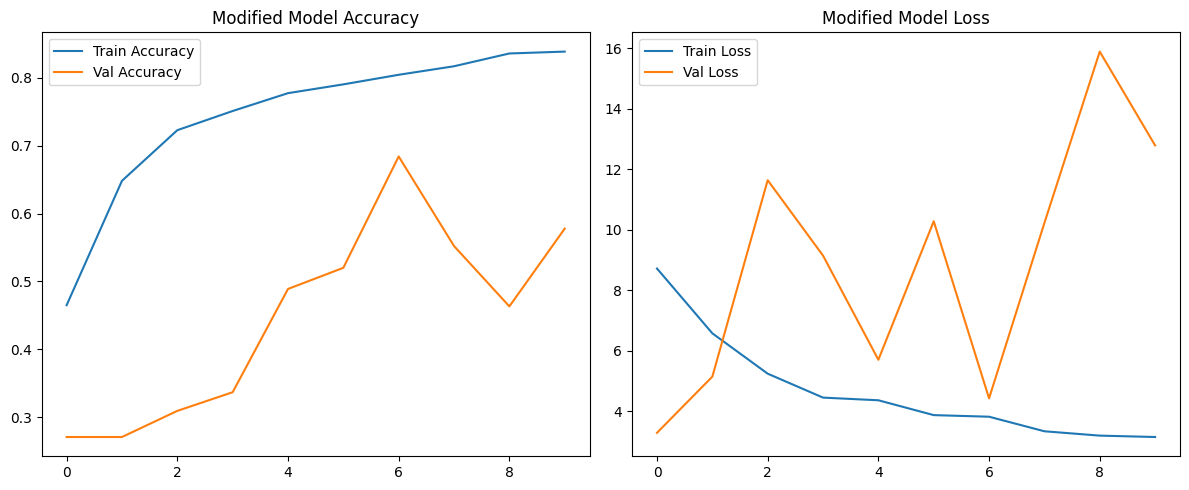

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history_modified.history['accuracy'], label='Train Accuracy')
plt.plot(history_modified.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title("Modified Model Accuracy")

plt.subplot(1,2,2)
plt.plot(history_modified.history['loss'], label='Train Loss')
plt.plot(history_modified.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Modified Model Loss")

plt.tight_layout()
plt.show()

## 6. Model Modifikasi 2 = Tuned Modified AlexNet

Berdasarkan hasil Model 1, model sudah mampu belajar dengan cukup baik pada data training, tetapi performa validation masih berfluktuasi dan validation loss cenderung tidak stabil. Hal ini menunjukkan bahwa masalah utama pada tahap ini adalah generalisasi model yang belum optimal.

Oleh karena itu, pada Model 2 dilakukan tuning terhadap arsitektur dan hyperparameter dengan tujuan meningkatkan stabilitas training. Pertama, learning rate diturunkan agar proses optimisasi berjalan lebih halus dan tidak terlalu agresif. Kedua, ukuran fully connected layer kembali diperkecil untuk mengurangi jumlah parameter dan menekan risiko overfitting. Ketiga, dropout diturunkan dari 0.5 menjadi 0.3 agar model tetap mendapatkan regularisasi, namun tidak kehilangan terlalu banyak informasi selama training.

Selain itu, digunakan callback EarlyStopping dan ReduceLROnPlateau untuk membantu menghentikan training ketika model tidak lagi membaik dan secara otomatis menurunkan learning rate saat performa validation stagnan. Dengan strategi ini, diharapkan Model 2 dapat menghasilkan performa validation yang lebih stabil dibandingkan Model 1.

In [30]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

model_2 = Sequential([
    Input(shape=(224, 224, 3)),

    Conv2D(96, (11,11), strides=4, activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(3,3), strides=2),

    Conv2D(256, (5,5), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(3,3), strides=2),

    Conv2D(384, (3,3), padding='same', activation='relu'),
    BatchNormalization(),

    Conv2D(384, (3,3), padding='same', activation='relu'),
    BatchNormalization(),

    Conv2D(256, (3,3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(3,3), strides=2),

    Flatten(),

    Dense(512, activation='relu'),
    Dropout(0.3),

    Dense(256, activation='relu'),
    Dropout(0.3),

    Dense(5, activation='softmax')
])

model_2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 54, 54, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 26, 26, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 12, 12, 384)    │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 12, 12, 384)    │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │     3,277,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,162,629 (27.32 MB)

 Trainable params: 7,159,877 (27.31 MB)

 Non-trainable params: 2,752 (10.75 KB)

## Compile Model

In [31]:
model_2.compile(
    optimizer=Adam(learning_rate=5e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

## Early Stoppig dan ReduceLROnplateau

Berdasarkan hasil Model Modifikasi 1, terlihat bahwa meskipun training accuracy meningkat secara signifikan, performa pada validation masih belum stabil dan cenderung berfluktuasi. Selain itu, validation loss menunjukkan nilai yang sangat besar dan tidak konsisten antar epoch. Hal ini mengindikasikan bahwa proses optimisasi masih terlalu agresif dan model berpotensi mengalami overfitting terhadap data training.

Untuk mengatasi permasalahan tersebut, pada Model Modifikasi 2 ditambahkan callback EarlyStopping dan ReduceLROnPlateau. EarlyStopping digunakan untuk menghentikan proses training secara otomatis ketika performa validation tidak lagi mengalami perbaikan. Dengan demikian, model tidak terus dilatih secara berlebihan yang dapat memperburuk overfitting.

Sementara itu, ReduceLROnPlateau digunakan untuk menurunkan learning rate ketika validation loss tidak menunjukkan peningkatan. Pada Model 1, learning rate yang tetap menyebabkan model terus melakukan update yang besar meskipun sudah mendekati kondisi optimal. Dengan menurunkan learning rate secara bertahap, proses optimisasi menjadi lebih halus sehingga model memiliki peluang lebih besar untuk mencapai titik konvergensi yang lebih baik.

Dengan penambahan kedua callback ini, Model Modifikasi 2 diharapkan dapat memiliki proses training yang lebih adaptif, lebih stabil, dan mampu meningkatkan performa validation dibandingkan Model Modifikasi 1.

In [32]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

## Training model

In [33]:
history_model_2 = model_2.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 23s 259ms/step - accuracy: 0.4663 - loss: 4.5394 - val_accuracy: 0.2711 - val_loss: 2.1196 - learning_rate: 5.0000e-05
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 248ms/step - accuracy: 0.6031 - loss: 3.7523 - val_accuracy: 0.2793 - val_loss: 1.7313 - learning_rate: 5.0000e-05
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 255ms/step - accuracy: 0.6961 - loss: 3.1545 - val_accuracy: 0.2436 - val_loss: 2.5138 - learning_rate: 5.0000e-05
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - accuracy: 0.7238 - loss: 2.9206
Epoch 4: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 265ms/step - accuracy: 0.7318 - loss: 2.8505 - val_accuracy: 0.3278 - val_loss: 3.9995 - learning_rate: 5.0000e-05
Epoch 5/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 265ms/step - accuracy: 0.7671 - loss: 2.5884 - val_accuracy: 0.3755 - val_loss: 5.4988 - learning_rate: 2.5000e-05


Berdasarkan hasil training Model 2, terlihat bahwa model mengalami peningkatan performa yang cukup baik pada data training. Akurasi training meningkat dari sekitar 46.63% pada epoch pertama menjadi sekitar 76–77% pada epoch ke-5. Hal ini menunjukkan bahwa model masih mampu mempelajari pola-pola penting dari data, sama seperti pada Model 1.

Namun, jika dibandingkan dengan Model 1, fokus utama pada Model 2 adalah stabilitas training. Dari hasil yang diperoleh, validation accuracy masih berada pada kisaran rendah hingga sedang (sekitar 24%–37%), dan belum menunjukkan peningkatan yang konsisten. Selain itu, validation loss juga masih cukup fluktuatif dan cenderung meningkat pada beberapa epoch, yang menunjukkan bahwa model masih kesulitan dalam melakukan generalisasi terhadap data validation.

Menariknya, pada epoch ke-4 terjadi penurunan learning rate secara otomatis melalui mekanisme ReduceLROnPlateau. Hal ini menunjukkan bahwa model mendeteksi stagnasi pada validation loss, sehingga learning rate diturunkan untuk membuat proses optimisasi menjadi lebih halus. Setelah penurunan learning rate, training tetap berjalan, tetapi peningkatan performa validation masih belum signifikan.

Jika dibandingkan dengan Model 1, Model 2 menunjukkan proses training yang lebih terkontrol dan tidak terlalu agresif. Learning rate yang lebih kecil serta penggunaan callback membantu menjaga stabilitas proses optimisasi. Namun demikian, performa validation yang masih fluktuatif menunjukkan bahwa permasalahan generalisasi belum sepenuhnya teratasi.

Secara keseluruhan, Model 2 dapat dikatakan lebih stabil dibandingkan Model 1 dari sisi proses training, tetapi belum memberikan peningkatan yang signifikan pada performa validation. Hal ini menunjukkan bahwa tuning hyperparameter saja belum cukup untuk mengatasi permasalahan, sehingga diperlukan pendekatan yang lebih kuat, seperti penggunaan arsitektur CNN yang lebih modern pada model berikutnya.

## 7. Model Modifiikasi 3 

Berdasarkan hasil Model 2, model sudah menunjukkan peningkatan dalam proses training, namun performa validation masih belum stabil dan cenderung berfluktuasi. Hal ini menunjukkan bahwa model masih mengalami kesulitan dalam melakukan generalisasi terhadap data baru.

Oleh karena itu, pada Model 3 dilakukan perubahan arsitektur dengan fokus utama pada peningkatan kemampuan generalisasi. Perubahan paling signifikan adalah mengganti Flatten layer dengan GlobalAveragePooling2D. Pendekatan ini digunakan untuk mengurangi jumlah parameter secara drastis sehingga model menjadi lebih ringan dan tidak mudah overfitting.

Selain itu, ditambahkan Dropout tidak hanya pada fully connected layer, tetapi juga setelah convolution block untuk membantu regularisasi pada feature extraction. Ukuran dense layer juga diperkecil agar kompleksitas model lebih sesuai dengan ukuran dataset.

Dengan modifikasi ini, Model 3 diharapkan mampu menghasilkan performa validation yang lebih stabil dan mengurangi gap antara training dan validation.

In [35]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Dense, Dropout, BatchNormalization,
    GlobalAveragePooling2D
)
from tensorflow.keras.optimizers import Adam

model_3 = Sequential([
    Input(shape=(224, 224, 3)),

    Conv2D(96, (11,11), strides=4, activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(3,3), strides=2),
    Dropout(0.2),

    Conv2D(256, (5,5), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(3,3), strides=2),
    Dropout(0.2),

    Conv2D(384, (3,3), padding='same', activation='relu'),
    BatchNormalization(),

    Conv2D(384, (3,3), padding='same', activation='relu'),
    BatchNormalization(),

    Conv2D(256, (3,3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(3,3), strides=2),
    Dropout(0.3),

    GlobalAveragePooling2D(),

    Dense(256, activation='relu'),
    Dropout(0.3),

    Dense(128, activation='relu'),
    Dropout(0.3),

    Dense(5, activation='softmax')
])

model_3.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 54, 54, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 26, 26, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 12, 12, 384)    │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 12, 12, 384)    │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 5)              │           64

 Total params: 3,852,037 (14.69 MB)

 Trainable params: 3,849,285 (14.68 MB)

 Non-trainable params: 2,752 (10.75 KB)

## Compile Model

In [36]:
model_3.compile(
    optimizer=Adam(learning_rate=3e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

## CallBack (Pakai Lagi)

In [37]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)


## Train Model 3

In [39]:
history_model_3 = model_3.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 25s 262ms/step - accuracy: 0.3890 - loss: 2.7988 - val_accuracy: 0.2711 - val_loss: 1.6799 - learning_rate: 3.0000e-05
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 248ms/step - accuracy: 0.5102 - loss: 2.1062 - val_accuracy: 0.2711 - val_loss: 2.0692 - learning_rate: 3.0000e-05
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.5811 - loss: 1.7567
Epoch 3: ReduceLROnPlateau reducing learning rate to 1.4999999621068127e-05.
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 262ms/step - accuracy: 0.5992 - loss: 1.6684 - val_accuracy: 0.2711 - val_loss: 2.6327 - learning_rate: 3.0000e-05
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 22s 270ms/step - accuracy: 0.6369 - loss: 1.4925 - val_accuracy: 0.2711 - val_loss: 2.7956 - learning_rate: 1.5000e-05


Berdasarkan hasil training Model 3, terlihat bahwa model masih mampu meningkatkan performa pada data training, di mana akurasi meningkat dari sekitar 38.90% pada epoch pertama menjadi sekitar 63–64% pada epoch ke-4. Hal ini menunjukkan bahwa model tetap memiliki kemampuan untuk mempelajari pola dari data training.

Namun, jika dilihat dari validation accuracy, performanya masih stagnan pada nilai sekitar 27.11% dan tidak menunjukkan peningkatan sama sekali. Selain itu, validation loss justru cenderung meningkat dari 1.67 menjadi lebih dari 2.7. Kondisi ini menunjukkan bahwa model tidak mampu melakukan generalisasi dengan baik terhadap data validation.

Pada epoch ke-3, ReduceLROnPlateau berhasil menurunkan learning rate karena validation loss tidak mengalami perbaikan. Hal ini menunjukkan bahwa mekanisme adaptif pada Model 3 sudah bekerja dengan baik. Namun, meskipun learning rate telah diturunkan, performa validation tetap tidak membaik secara signifikan.

Jika dibandingkan dengan Model 2, Model 3 menunjukkan proses training yang lebih terkontrol dengan learning rate yang lebih kecil dan penggunaan arsitektur yang lebih ringan. Akan tetapi, hasil ini menunjukkan bahwa perbaikan arsitektur yang dilakukan belum cukup untuk meningkatkan kemampuan generalisasi model.

Secara keseluruhan, Model 3 masih mengalami kesulitan dalam memahami pola data secara menyeluruh, terutama pada data validation. Hal ini menunjukkan bahwa pendekatan model manual mulai mencapai batasnya dalam menangani kompleksitas dataset ini.

Oleh karena itu, diperlukan pendekatan yang lebih kuat, yaitu menggunakan arsitektur berbasis transfer learning seperti EfficientNetB0, yang diharapkan mampu memberikan performa yang lebih baik.

## Plot Model 3

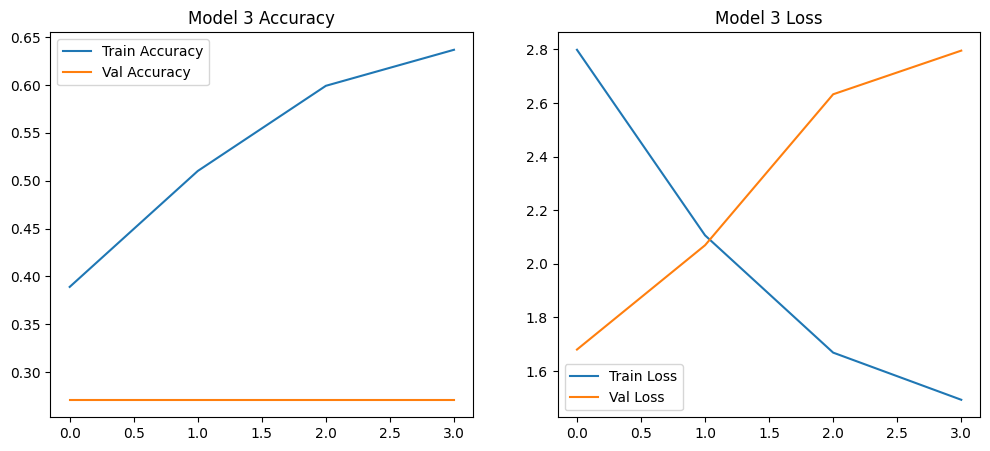

In [40]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history_model_3.history['accuracy'], label='Train Accuracy')
plt.plot(history_model_3.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title("Model 3 Accuracy")

plt.subplot(1,2,2)
plt.plot(history_model_3.history['loss'], label='Train Loss')
plt.plot(history_model_3.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Model 3 Loss")

plt.show()

Berdasarkan visualisasi plot Model 3, terlihat bahwa training accuracy mengalami peningkatan yang cukup konsisten dari epoch ke epoch. Hal ini menunjukkan bahwa model masih mampu mempelajari pola dari data training dengan baik.

Namun, jika dibandingkan dengan validation accuracy, terlihat bahwa nilainya cenderung stagnan dan tidak mengalami peningkatan yang berarti. Gap yang cukup besar antara training accuracy dan validation accuracy menunjukkan bahwa model mengalami kesulitan dalam melakukan generalisasi terhadap data yang belum pernah dilihat sebelumnya.

Selain itu, dari plot loss terlihat bahwa training loss terus menurun, yang menandakan bahwa model semakin baik dalam meminimalkan error pada data training. Sebaliknya, validation loss justru menunjukkan tren meningkat, yang mengindikasikan bahwa performa model pada data validation semakin memburuk seiring bertambahnya epoch.

Kombinasi dari pola ini menunjukkan adanya overfitting, di mana model terlalu fokus mempelajari data training namun gagal menangkap pola yang lebih umum. Dengan demikian, meskipun Model 3 memiliki proses pembelajaran yang baik pada training, model ini belum berhasil meningkatkan kemampuan generalisasi dibandingkan model sebelumnya.

## 8. Model Modifikasi 4 (Disini Saya Juga Melakukan Testing 3 Kali), tapi Tidak Diperlihatkan

Berdasarkan hasil tiga model sebelumnya, permasalahan utama yang masih muncul adalah rendahnya kemampuan generalisasi, yang terlihat dari validation accuracy yang belum stabil dan validation loss yang masih tinggi. Hal ini menunjukkan bahwa pendekatan model manual mulai mencapai batasnya dalam menangani kompleksitas dataset.

Oleh karena itu, pada Model 4 digunakan arsitektur EfficientNetB0 berbasis transfer learning. Model ini dipilih karena telah dilatih pada dataset besar sebelumnya, sehingga sudah mampu mengenali fitur-fitur visual umum seperti tepi, tekstur, pola warna, dan bentuk. Dengan demikian, model tidak perlu belajar sepenuhnya dari awal.

Namun, berdasarkan beberapa percobaan yang dilakukan pada model EfficientNetB0, ditemukan beberapa kendala pada konfigurasi awal. Pada percobaan pertama, performa model masih sangat rendah dan mendekati tebakan acak. Hal ini disebabkan oleh ketidaksesuaian preprocessing input dengan kebutuhan model pre-trained, sehingga fitur yang telah dipelajari oleh EfficientNet tidak dapat dimanfaatkan secara optimal.

Pada percobaan kedua, meskipun preprocessing telah diperbaiki, performa model masih belum stabil. Hal ini diduga disebabkan oleh konfigurasi training yang belum optimal, seperti learning rate dan struktur classifier head yang kurang sesuai, sehingga model belum mampu beradaptasi dengan baik terhadap dataset.

Pada percobaan ketiga, penggunaan class weight dan data augmentation yang cukup agresif justru membuat proses training menjadi terlalu kompleks. Hal ini menyebabkan model kesulitan dalam menemukan pola yang konsisten, sehingga validation accuracy tetap rendah dan tidak stabil.

Berdasarkan hasil dari beberapa percobaan tersebut, dilakukan penyesuaian pada pipeline Model 4 dengan menyederhanakan data augmentation, menghilangkan sementara penggunaan class weight, serta menyesuaikan struktur classifier head agar lebih sesuai dengan dataset. Dengan pendekatan ini, model diharapkan dapat belajar secara lebih stabil terlebih dahulu sebelum dilakukan eksperimen lanjutan seperti fine-tuning.

Pendekatan bertahap ini menunjukkan bahwa keberhasilan transfer learning tidak hanya bergantung pada pemilihan arsitektur, tetapi juga pada kesesuaian preprocessing dan konfigurasi training yang digunakan.

## Generator Baru Khusus Untuk EfficientNet

Untuk tf.keras.applications.EfficientNetB0, model ini sudah punya preprocessing internal, sehingga input umumnya diharapkan dalam skala yang sesuai pipeline bawaan model. Akibatnya, kalau kamu masih rescale=1./255 di generator, input bisa jadi terlalu kecil / tidak sesuai distribusi yang diharapkan pretrained backbone.

In [57]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen_eff = ImageDataGenerator(
    validation_split=0.3,
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True
)

val_test_datagen_eff = ImageDataGenerator(
    validation_split=0.3
)

Load ulang datanya

In [58]:
train_data_eff = train_datagen_eff.flow_from_directory(
    DATASET_PATH,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_data_eff = val_test_datagen_eff.flow_from_directory(
    DATASET_PATH,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

test_data_eff = val_test_datagen_eff.flow_from_directory(
    DATASET_PATH,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 2550 images belonging to 5 classes.
Found 1092 images belonging to 5 classes.
Found 1092 images belonging to 5 classes.


## Build Model Modif 4

In [60]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam

base_model = EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model_4 = Sequential([
    Input(shape=(224, 224, 3)),
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(5, activation='softmax')
])

model_4.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_4.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,378,792 (16.70 MB)

 Trainable params: 329,221 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

## CallBack

In [61]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

## Training Model Modifikasi 4

In [62]:
history_model_4 = model_4.fit(
    train_data_eff,
    validation_data=val_data_eff,
    epochs=10,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 45s 480ms/step - accuracy: 0.8549 - loss: 0.3878 - val_accuracy: 0.8718 - val_loss: 0.4018 - learning_rate: 0.0010
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 28s 340ms/step - accuracy: 0.9376 - loss: 0.1617 - val_accuracy: 0.8599 - val_loss: 0.4077 - learning_rate: 0.0010
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 30s 369ms/step - accuracy: 0.9549 - loss: 0.1269 - val_accuracy: 0.9167 - val_loss: 0.2921 - learning_rate: 0.0010
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 35s 436ms/step - accuracy: 0.9647 - loss: 0.0916 - val_accuracy: 0.8910 - val_loss: 0.3518 - learning_rate: 0.0010
Epoch 5/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.9761 - loss: 0.0673 - val_accuracy: 0.9176 - val_loss: 0.2909 - learning_rate: 0.0010
Epoch 6/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 46s 570ms/step - accuracy: 0.9698 - loss: 0.0780 - val_accuracy: 0.9084 - val_loss: 0.3401 - learning_rate: 0.0010
Epoch 7/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step - accuracy: 0.9682 - loss: 0.0817

Berdasarkan hasil training Model 4 menggunakan EfficientNetB0, terlihat peningkatan performa yang sangat signifikan dibandingkan model-model sebelumnya. Pada epoch pertama saja, model sudah mencapai training accuracy sebesar sekitar 85% dan validation accuracy sekitar 87%, yang menunjukkan bahwa model langsung mampu memanfaatkan fitur-fitur pre-trained secara efektif.

Seiring bertambahnya epoch, training accuracy terus meningkat hingga mencapai lebih dari 97%, sementara validation accuracy juga mencapai nilai di atas 90% pada beberapa epoch, dengan nilai tertinggi sekitar 91–92%. Hal ini menunjukkan bahwa model memiliki kemampuan generalisasi yang jauh lebih baik dibandingkan model manual sebelumnya.

Selain itu, nilai validation loss juga relatif rendah dan cukup stabil dibandingkan model sebelumnya. Meskipun terdapat sedikit fluktuasi pada beberapa epoch, secara keseluruhan model tidak menunjukkan gejala overfitting yang signifikan. Hal ini menunjukkan bahwa kombinasi transfer learning, penyederhanaan preprocessing, serta penyesuaian konfigurasi training berhasil meningkatkan stabilitas model.

Jika dibandingkan dengan Model 1, Model 2, dan Model 3, perbedaan performa sangat jelas. Model-model manual sebelumnya mengalami kesulitan dalam mencapai akurasi tinggi dan menunjukkan validation yang tidak stabil, sedangkan EfficientNetB0 mampu memberikan performa tinggi secara konsisten.

Dengan demikian, dapat disimpulkan bahwa penggunaan transfer learning melalui EfficientNetB0 merupakan pendekatan yang paling efektif untuk dataset ini, karena mampu mengatasi keterbatasan data, meningkatkan akurasi secara signifikan, serta memberikan generalisasi yang lebih baik.

Berdasarkan hasil tersebut, Model 4 merupakan model terbaik di antara seluruh eksperimen yang dilakukan. Model ini tidak hanya mencapai akurasi yang tinggi, tetapi juga menunjukkan stabilitas training dan kemampuan generalisasi yang baik.

Keberhasilan ini menunjukkan bahwa arsitektur berbasis transfer learning seperti EfficientNetB0 lebih cocok digunakan dibandingkan model CNN manual untuk dataset dengan ukuran terbatas. Oleh karena itu, Model 4 dipilih sebagai model final untuk digunakan pada tahap evaluasi selanjutnya.

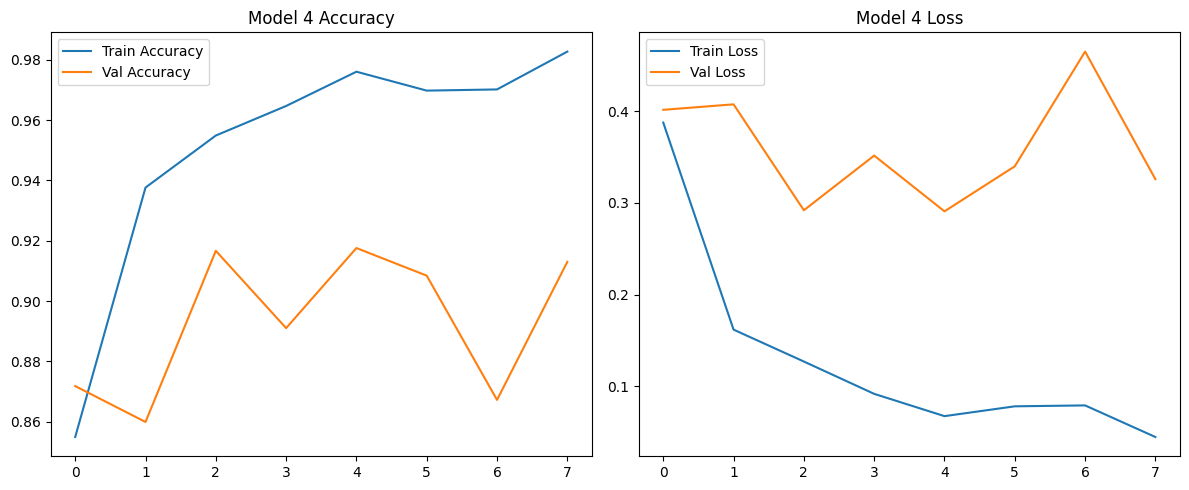

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history_model_4.history['accuracy'], label='Train Accuracy')
plt.plot(history_model_4.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title("Model 4 Accuracy")

plt.subplot(1,2,2)
plt.plot(history_model_4.history['loss'], label='Train Loss')
plt.plot(history_model_4.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Model 4 Loss")

plt.tight_layout()
plt.show()

Berdasarkan grafik Model 4, terlihat bahwa training accuracy meningkat secara cepat dan konsisten hingga mendekati nilai maksimal (mendekati 100%). Hal ini menunjukkan bahwa model mampu mempelajari pola pada data training dengan sangat baik.

Sementara itu, validation accuracy juga menunjukkan performa yang tinggi dan relatif stabil, berada pada kisaran sekitar 85% hingga lebih dari 90%. Meskipun terdapat sedikit fluktuasi antar epoch, nilai validation accuracy tetap berada pada level tinggi, yang menandakan bahwa model memiliki kemampuan generalisasi yang baik.

Dari sisi loss, training loss mengalami penurunan yang signifikan seiring bertambahnya epoch, yang menunjukkan bahwa model semakin baik dalam meminimalkan error pada data training. Validation loss juga relatif stabil, meskipun terdapat beberapa kenaikan pada titik tertentu. Fluktuasi ini masih dalam batas wajar dan tidak menunjukkan overfitting yang parah.

Jika dibandingkan dengan model-model sebelumnya, perbedaan performa sangat jelas. Model 4 tidak hanya mencapai akurasi yang tinggi, tetapi juga menunjukkan keseimbangan yang baik antara training dan validation, yang menandakan bahwa model tidak hanya menghafal data, tetapi benar-benar memahami pola yang ada.

Secara keseluruhan, grafik ini menunjukkan bahwa penggunaan EfficientNetB0 dengan konfigurasi yang tepat berhasil menghasilkan model yang stabil, akurat, dan memiliki generalisasi yang baik.

# 2d. [LO2, LO3, & LO4 – 15 Points] Lakukan evaluasi performa model anda pada data test dengan menggunakan minimal 3 evaluation metrics. Analisis, jelaskan, dan simpulkan hasilnya. Lalu, berikan saran untuk pengembangan lebih lanjut dari model anda.

# D. Masuk Ke Data Testing dan Evaluation Metrics

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

## 1. Pastikan Test Data Sudah Disiapkan Dengan Shuffle = False

In [68]:
DATASET_PATH = "data/cherry"

test_datagen_eff = ImageDataGenerator(
    validation_split=0.3
)

test_data = test_datagen_eff.flow_from_directory(
    DATASET_PATH,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 1092 images belonging to 5 classes.


## 2. EVALUASI LOSS DAN ACCURACY LANGSUNG DARI MODEL


In [69]:
test_loss, test_accuracy = model_4.evaluate(test_data, verbose=1)

print("Test Loss     :", round(test_loss, 4))
print("Test Accuracy :", round(test_accuracy, 4))

35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 236ms/step - accuracy: 0.9176 - loss: 0.2909
Test Loss     : 0.2909
Test Accuracy : 0.9176


## 3. Prediksi Pada Test Data

In [70]:
y_prob = model_4.predict(test_data, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
y_true = test_data.classes

class_names = list(test_data.class_indices.keys())

print("Jumlah data test :", len(y_true))
print("Jumlah prediksi  :", len(y_pred))
print("Class names      :", class_names)

35/35 ━━━━━━━━━━━━━━━━━━━━ 8s 191ms/step
Jumlah data test : 1092
Jumlah prediksi  : 1092
Class names      : ['Cherry_Leaf_Scorch', 'Cherry_Normal_leaf', 'Cherry_brown_spot', 'Cherry_purple_leaf_spot', 'Cherry_shot_hole_disease']


## 4. Hitung Evaluation Metrics Utama

In [71]:
acc = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

print("Accuracy  :", round(acc, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1-Score  :", round(f1, 4))

Accuracy  : 0.9176
Precision : 0.9286
Recall    : 0.9176
F1-Score  : 0.9185


Berdasarkan hasil evaluasi pada data test, Model 4 menunjukkan performa yang sangat baik pada seluruh metrik yang digunakan.

Nilai accuracy sebesar 91.76% menunjukkan bahwa sebagian besar data berhasil diklasifikasikan dengan benar oleh model. Hal ini mengindikasikan bahwa model memiliki tingkat ketepatan yang tinggi dalam memprediksi kelas dari citra yang diberikan.

Nilai precision sebesar 92.86% menunjukkan bahwa ketika model melakukan prediksi terhadap suatu kelas, mayoritas prediksi tersebut benar. Dengan kata lain, tingkat kesalahan false positive relatif rendah, sehingga model tidak banyak melakukan kesalahan dalam mengklasifikasikan gambar ke kelas yang salah.

Nilai recall sebesar 91.76% menunjukkan bahwa model mampu mendeteksi sebagian besar data pada setiap kelas dengan baik. Artinya, jumlah data yang seharusnya masuk ke suatu kelas dan berhasil dikenali oleh model cukup tinggi, sehingga kesalahan false negative relatif kecil.

Nilai F1-score sebesar 91.85% menunjukkan keseimbangan yang baik antara precision dan recall. Hal ini menandakan bahwa model tidak hanya akurat, tetapi juga konsisten dalam mengenali seluruh kelas tanpa bias yang signifikan terhadap kelas tertentu.

Secara keseluruhan, kombinasi nilai accuracy, precision, recall, dan F1-score yang tinggi menunjukkan bahwa Model 4 memiliki performa yang sangat baik dan mampu melakukan klasifikasi secara akurat serta stabil pada data yang belum pernah dilihat sebelumnya.

## 5. Classification Report

In [72]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

                          precision    recall  f1-score   support

      Cherry_Leaf_Scorch     0.9778    0.9333    0.9550       330
      Cherry_Normal_leaf     0.9068    0.7133    0.7985       150
       Cherry_brown_spot     0.8980    0.9565    0.9263       184
 Cherry_purple_leaf_spot     1.0000    0.9527    0.9758       296
Cherry_shot_hole_disease     0.7127    0.9773    0.8243       132

                accuracy                         0.9176      1092
               macro avg     0.8990    0.9066    0.8960      1092
            weighted avg     0.9286    0.9176    0.9185      1092



## 7. Confussion Matrix

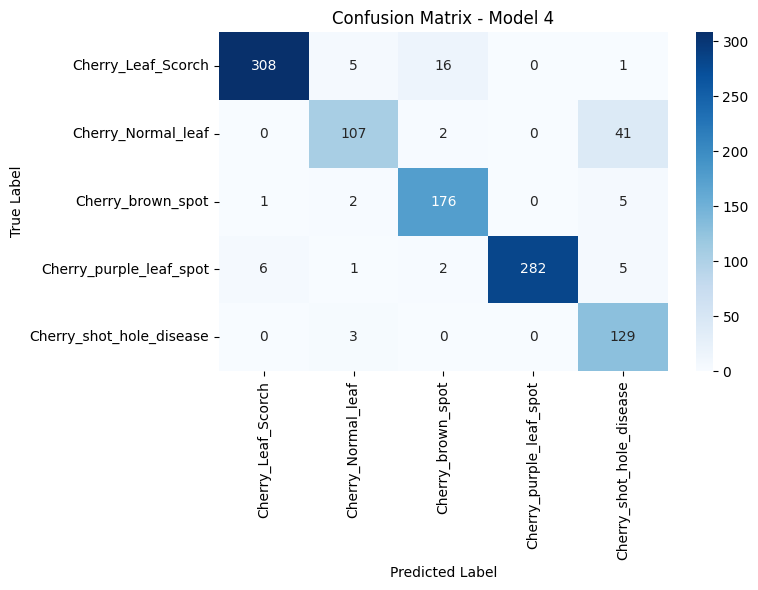

In [74]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix - Model 4")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

Berdasarkan hasil classification report, terlihat bahwa performa Model 4 sangat baik secara keseluruhan, namun terdapat variasi performa antar kelas yang menarik untuk dianalisis lebih lanjut.

Pada kelas **Cherry_Leaf_Scorch**, model menunjukkan performa yang sangat tinggi dengan precision sebesar 97.78% dan recall sebesar 93.33%, menghasilkan F1-score sebesar 95.50%. Hal ini menunjukkan bahwa model mampu mengenali kelas ini dengan sangat baik, baik dari sisi ketepatan prediksi maupun kelengkapan deteksi.

Pada kelas **Cherry_purple_leaf_spot**, performa model bahkan lebih tinggi lagi, dengan precision mencapai 100% dan recall sebesar 95.27%. Ini berarti hampir semua prediksi untuk kelas ini benar, dan sebagian besar data berhasil terdeteksi, sehingga menghasilkan F1-score yang sangat tinggi (97.58%).

Kelas **Cherry_brown_spot** juga menunjukkan performa yang stabil dengan recall tinggi (95.65%), yang berarti model mampu mendeteksi hampir seluruh data pada kelas ini. Meskipun precision sedikit lebih rendah (89.80%), nilai F1-score tetap tinggi (92.63%), menunjukkan keseimbangan yang baik.

Namun, pada kelas **Cherry_Normal_leaf**, terlihat bahwa recall cukup rendah (71.33%) dibandingkan precision (90.68%). Hal ini menunjukkan bahwa model cukup baik dalam memprediksi kelas ini ketika yakin, tetapi masih banyak data yang seharusnya masuk ke kelas ini tidak terdeteksi (false negative cukup tinggi).

Sebaliknya, pada kelas **Cherry_shot_hole_disease**, terjadi pola yang berlawanan. Recall sangat tinggi (97.73%), tetapi precision lebih rendah (71.27%). Ini berarti model mampu menangkap hampir semua data dari kelas ini, namun sering salah mengklasifikasikan data dari kelas lain sebagai kelas ini (false positive tinggi).

Secara keseluruhan, nilai macro average menunjukkan bahwa performa antar kelas cukup seimbang, meskipun masih terdapat beberapa kelas yang lebih sulit dipelajari. Sementara itu, weighted average yang tinggi menunjukkan bahwa model bekerja sangat baik secara keseluruhan, terutama pada kelas dengan jumlah data yang lebih besar.

Dengan demikian, dapat disimpulkan bahwa Model 4 memiliki performa yang sangat baik, namun masih dapat ditingkatkan pada beberapa kelas tertentu, khususnya dalam menyeimbangkan precision dan recall agar kesalahan klasifikasi dapat diminimalkan.

## 9. Evaluasi Semua Model 

In [78]:
def evaluate_model(model, test_data, model_name="Model"):
    y_prob = model.predict(test_data, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    y_true = test_data.classes

    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

In [80]:
results = []

results.append(evaluate_model(alexnet_model, test_data, "Baseline AlexNet"))
results.append(evaluate_model(modified_alexnet, test_data, "Model 1"))
results.append(evaluate_model(model_2, test_data, "Model 2"))
results.append(evaluate_model(model_3, test_data, "Model 3"))
results.append(evaluate_model(model_4, test_data, "Model 4 - EfficientNetB0"))

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Baseline AlexNet,0.271062,0.073475,0.271062,0.115612
1,Model 1,0.244505,0.332925,0.244505,0.173440
2,Model 2,0.293040,0.153052,0.293040,0.188569
3,Model 3,0.120879,0.014612,0.120879,0.026072
4,Model 4 - EfficientNetB0,0.917582,0.928558,0.917582,0.918513


Berdasarkan hasil evaluasi seluruh model, terlihat bahwa setiap model memiliki kelemahan yang berbeda, dan proses pengembangan model dilakukan secara bertahap untuk memperbaiki kelemahan tersebut hingga akhirnya diperoleh Model 4 sebagai model terbaik.

Pada **Baseline AlexNet**, permasalahan utamanya adalah model belum mampu belajar dengan baik. Hal ini terlihat dari nilai accuracy, precision, recall, dan F1-score yang sangat rendah. Model baseline cenderung gagal menangkap pola penting dari data, sehingga performanya masih mendekati tebakan acak. Dengan kata lain, kelemahan utama baseline adalah **underfitting** dan kegagalan model dalam mempelajari representasi fitur yang relevan.

Untuk mengatasi hal tersebut, dibuat **Model 1 (Modified AlexNet)** dengan menambahkan Batch Normalization dan memperkecil fully connected layer. Perubahan ini berhasil membuat model mulai belajar, yang sebelumnya tidak terjadi pada baseline. Namun, setelah dievaluasi pada data test, performanya masih belum baik. Artinya, meskipun model sudah lebih mampu belajar pada data training, model masih belum dapat melakukan generalisasi dengan baik pada data baru. Jadi, kelemahan utama Model 1 adalah **model sudah belajar, tetapi belum stabil dan masih belum efektif pada data test**.

Selanjutnya, dibuat **Model 2** dengan melakukan tuning hyperparameter, seperti menurunkan learning rate, menyesuaikan dropout, dan menggunakan callback seperti EarlyStopping serta ReduceLROnPlateau. Tujuan utamanya adalah memperbaiki ketidakstabilan training pada Model 1. Hasilnya, proses training memang menjadi lebih terkontrol, tetapi evaluasi test menunjukkan bahwa peningkatan performa masih sangat terbatas. Ini berarti kelemahan Model 2 adalah **stabilitas training membaik, tetapi kemampuan generalisasi model masih lemah**.

Pada **Model 3**, dilakukan perubahan arsitektur lanjutan dengan fokus pada peningkatan generalisasi, misalnya dengan mengganti Flatten menjadi GlobalAveragePooling2D, menambah dropout di convolution block, dan memperkecil dense layer. Secara teori, perubahan ini ditujukan untuk mengurangi overfitting dan membuat model lebih ringan. Namun, hasil evaluasi justru menunjukkan bahwa performa Model 3 menjadi lebih rendah dibanding Model 1 dan Model 2. Hal ini menunjukkan bahwa perbaikan arsitektur manual yang dilakukan belum cukup untuk mengatasi kompleksitas dataset. Dengan demikian, kelemahan utama Model 3 adalah **pendekatan model manual mulai mencapai batasnya dan tidak lagi efektif untuk meningkatkan performa**.

Setelah tiga model manual diuji, terlihat pola yang jelas bahwa permasalahan utama bukan hanya pada stabilitas training, tetapi pada keterbatasan model manual dalam mengekstraksi fitur secara optimal dari dataset citra daun cherry. Oleh karena itu, pada **Model 4** digunakan pendekatan transfer learning dengan EfficientNetB0.

Namun, Model 4 juga tidak langsung berhasil pada percobaan pertama. Pada percobaan awal, performa model masih rendah karena preprocessing dan konfigurasi input belum sesuai dengan kebutuhan model pre-trained. Pada percobaan kedua, meskipun ada perbaikan pada pipeline, hasilnya masih belum stabil karena konfigurasi training dan struktur classifier head belum optimal. Pada percobaan ketiga, dilakukan penyesuaian yang lebih tepat, yaitu dengan menyederhanakan data augmentation, menghilangkan sementara class weight, serta menyesuaikan classifier head agar lebih sesuai dengan karakteristik dataset. Setelah konfigurasi ini diperbaiki, Model 4 akhirnya menunjukkan peningkatan performa yang sangat signifikan.

Hasil akhir menunjukkan bahwa **Model 4 berhasil memperbaiki seluruh kelemahan model-model sebelumnya**. Jika baseline gagal belajar, Model 4 mampu belajar dengan sangat baik. Jika Model 1 dan Model 2 masih lemah dalam generalisasi, Model 4 menunjukkan validation dan test performance yang tinggi serta stabil. Jika Model 3 menunjukkan keterbatasan arsitektur manual, Model 4 mampu mengatasi masalah tersebut dengan memanfaatkan fitur pre-trained dari EfficientNetB0.

Dengan demikian, dapat disimpulkan bahwa proses pengembangan model berjalan secara bertahap dan logis. Setiap model digunakan untuk mengidentifikasi kelemahan sebelumnya, hingga akhirnya seluruh kelemahan utama tersebut dapat diatasi pada Model 4. Oleh karena itu, EfficientNetB0 dipilih sebagai model final karena memberikan performa terbaik, paling stabil, dan paling mampu melakukan generalisasi pada dataset ini.

# MODELLL TEBRAIKKK !!!

In [81]:
best_model_idx = results_df["Accuracy"].idxmax()
best_model_name = results_df.loc[best_model_idx, "Model"]
best_model_acc = results_df.loc[best_model_idx, "Accuracy"]

print("Model terbaik berdasarkan accuracy:", best_model_name)
print("Accuracy:", round(best_model_acc * 100, 2), "%")

Model terbaik berdasarkan accuracy: Model 4 - EfficientNetB0
Accuracy: 91.76 %


## 10. AUC Untuk Model 4 - EfficientNetB0

In [83]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

In [82]:
y_true = test_data.classes
y_score = model_4.predict(test_data, verbose=1)

class_names = list(test_data.class_indices.keys())
n_classes = len(class_names)

print("Jumlah kelas:", n_classes)
print("Shape y_score:", y_score.shape)

35/35 ━━━━━━━━━━━━━━━━━━━━ 7s 191ms/step
Jumlah kelas: 5
Shape y_score: (1092, 5)


In [84]:
y_true_bin = label_binarize(y_true, classes=np.arange(n_classes))

print("Shape y_true_bin:", y_true_bin.shape)

Shape y_true_bin: (1092, 5)


## MultiClass

In [85]:
auc_macro_ovr = roc_auc_score(
    y_true_bin,
    y_score,
    multi_class='ovr',
    average='macro'
)

auc_weighted_ovr = roc_auc_score(
    y_true_bin,
    y_score,
    multi_class='ovr',
    average='weighted'
)

auc_macro_ovo = roc_auc_score(
    y_true_bin,
    y_score,
    multi_class='ovo',
    average='macro'
)

auc_weighted_ovo = roc_auc_score(
    y_true_bin,
    y_score,
    multi_class='ovo',
    average='weighted'
)

print("AUC Macro OvR    :", round(auc_macro_ovr, 4))
print("AUC Weighted OvR :", round(auc_weighted_ovr, 4))
print("AUC Macro OvO    :", round(auc_macro_ovo, 4))
print("AUC Weighted OvO :", round(auc_weighted_ovo, 4))

AUC Macro OvR    : 0.9909
AUC Weighted OvR : 0.9919
AUC Macro OvO    : 0.9909
AUC Weighted OvO : 0.9919


## Per Kelas

In [86]:
fpr = {}
tpr = {}
roc_auc = {}

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

for i, class_name in enumerate(class_names):
    print(f"{class_name}: AUC = {roc_auc[i]:.4f}")

Cherry_Leaf_Scorch: AUC = 0.9902
Cherry_Normal_leaf: AUC = 0.9745
Cherry_brown_spot: AUC = 0.9943
Cherry_purple_leaf_spot: AUC = 0.9993
Cherry_shot_hole_disease: AUC = 0.9961


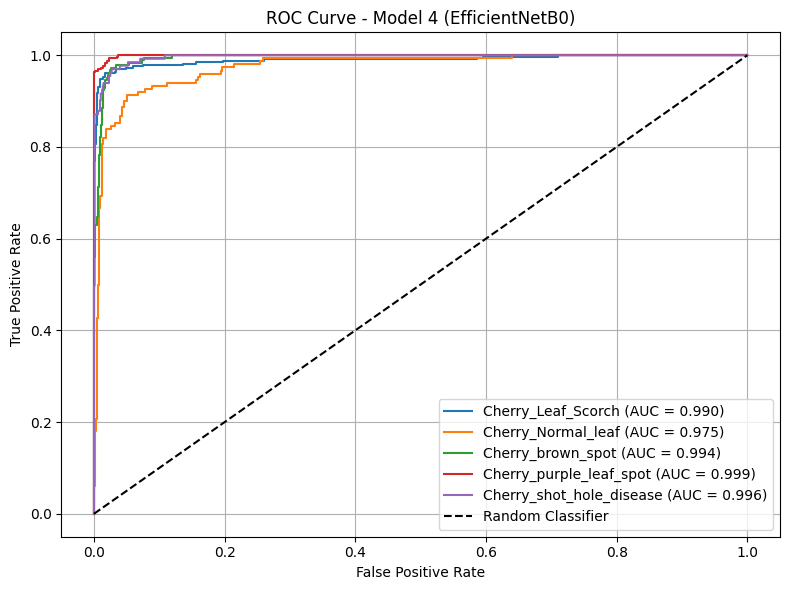

In [88]:
plt.figure(figsize=(8, 6))

for i, class_name in enumerate(class_names):
    plt.plot(
        fpr[i],
        tpr[i],
        label=f"{class_name} (AUC = {roc_auc[i]:.3f})"
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Model 4 (EfficientNetB0)")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

Berdasarkan grafik ROC Curve pada Model 4 (EfficientNetB0), terlihat bahwa seluruh kurva untuk masing-masing kelas berada sangat dekat dengan sudut kiri atas, yang menunjukkan performa klasifikasi yang sangat baik. Hal ini menandakan bahwa model memiliki kemampuan yang tinggi dalam membedakan antara kelas positif dan negatif untuk setiap kategori.

Nilai AUC untuk setiap kelas juga sangat tinggi (mendekati 1), yang mengindikasikan bahwa model hampir sempurna dalam melakukan separasi antar kelas. Tidak ada kelas yang menunjukkan performa rendah, sehingga dapat disimpulkan bahwa model bekerja secara konsisten pada seluruh kategori penyakit daun cherry.

Selain itu, jarak yang jauh antara kurva ROC dengan garis diagonal (random classifier) menunjukkan bahwa model jauh lebih baik dibandingkan tebakan acak. Hal ini memperkuat bahwa model memiliki kemampuan diskriminasi yang sangat kuat terhadap fitur-fitur citra.

Secara keseluruhan, hasil ROC dan AUC ini mengkonfirmasi bahwa Model 4 tidak hanya memiliki akurasi tinggi, tetapi juga memiliki kemampuan klasifikasi yang sangat baik pada semua kelas, sehingga sangat layak digunakan sebagai model final.